# Classifier Guidance


In [10]:
# imports
import numpy as np
import pandas as pd
import matplotlib
from pathlib import Path

import torch
from torch import nn
import torch.nn.functional as F
import sklearn.metrics

from torch.utils.data import DataLoader
from utils import load_data

from protgen.data import FAMILIES
from protgen.models.rnn import RNNEncoder
from protgen.models.classifier import ProteinFamilyClassifier

DEVICE = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
print(f"Device: {DEVICE}")

Device: cuda


## Data

In [11]:
# load data
data_train, train_loader, X_train, y_train = load_data(
    data_dir_path="../data", 
    type="train", 
    task="classification"
)

data_val, val_loader, X_val, y_val = load_data(
    data_dir_path="../data", 
    type="val", 
    task="classification"
)

data_test, test_loader, X_test, y_test = load_data(
    data_dir_path="../data", 
    type="test", 
    task="classification"
)

print('\n',repr(data_train),'\n',repr(data_val))

# train data, task: classification
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020])
# val data, task: classification
 Tokens shape: torch.Size([2001, 129])
 Labels (shape): torch.Size([2001])
# test data, task: classification
 Tokens shape: torch.Size([2001, 129])
 Labels (shape): torch.Size([2001])

 ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129) 
 ProteinDataset(num_samples=2001, vocab_size=23, num_classes=3, max_length=129)


In [12]:
# check class balance per split before doing anything
# this way we're shure that each protein family is represented equally in training and val
counts = pd.DataFrame({"train": data_train.df.family.value_counts(),
                       "val": data_val.df.family.value_counts(),
                       "test": data_test.df.family.value_counts()}
                       ).loc[list(FAMILIES)]
print(counts)

        train  val  test
family                  
AcyP     5340  667   667
HPr      5340  667   667
HU       5340  667   667


In [13]:
# prefix mask for loss calculation downstream
# mask PAD and BOS tokens, so that we don't include multiple copies of the full sequence
def prefix_mask(data):
    pos = torch.arange(data.max_length)
    lengths = torch.tensor(data.lengths)
    return (pos >= 1) & (pos <= lengths[:, None] + 1)   # (N, 129) bool, <EOS> included

mask_train, mask_val, mask_test = prefix_mask(data_train), prefix_mask(data_val), prefix_mask(data_test)

# expand Y to carry the family label at every position
# now each prefix can be used as its own training example
Y_train = y_train[:, None].expand(-1, data_train.max_length)
Y_val = y_val[:, None].expand(-1, data_val.max_length)
Y_test = y_test[:, None].expand(-1, data_test.max_length)

print(f"{int(mask_train.sum()):,} train prefixes from {len(data_train):,} sequences "
      f"({mask_train.sum() / len(data_train):.0f} each)")

1,537,909 train prefixes from 16,020 sequences (96 each)


## Encoding

In [14]:
# load the frozen RNN encoder config and weights
VOCAB_SIZE, NUM_CLASSES = data_train.vocab_size, len(data_train.fam_to_idx)

ckpt = torch.load("../results/rnn.pt", map_location=DEVICE)
encoder = RNNEncoder(**ckpt["config"]).to(DEVICE)
encoder.load_state_dict(ckpt["state_dict"])
encoder.eval().requires_grad_(False)

RNNEncoder(
  (embed): Embedding(23, 64, padding_idx=0)
  (embed_drop): Dropout(p=0.1, inplace=False)
  (lstm): LSTM(64, 256, num_layers=2, batch_first=True, dropout=0.2)
  (norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
  (out_drop): Dropout(p=0.2, inplace=False)
  (l_out): Linear(in_features=256, out_features=23, bias=False)
)

In [15]:
tri = torch.tril(torch.ones(X_train.shape[1], X_train.shape[1], dtype=torch.long, device=DEVICE))

def make_prefixes(X, Y, M):
    Xp = X[:, None, :] * tri[None] 
    return Xp[M], Y[M]   

## Classifier Training

In [16]:
# train two classification heads (one for generation and one for scoring)
# this way we don't get an optimistic evaluation
lr = 1e-3
batch_size = 1024
epochs = 50

torch.manual_seed(0) # head = nn.Linear(H_train.shape[-1], NUM_CLASSES).to(DEVICE)
head = ProteinFamilyClassifier(num_features=129, embedding_dim=32, num_hidden=128, num_output=NUM_CLASSES, vocab_size=VOCAB_SIZE).to(DEVICE)
torch.manual_seed(1) # eval_head = nn.Linear(H_train.shape[-1], NUM_CLASSES).to(DEVICE)
eval_head = ProteinFamilyClassifier(num_features=129, embedding_dim=32, num_hidden=128, num_output=NUM_CLASSES, vocab_size=VOCAB_SIZE).to(DEVICE)
opt = torch.optim.Adam([*head.parameters(), *eval_head.parameters()], lr=lr)

losses_head = []
val_losses_head = []

losses_eval_head = []
val_losses_eval_head = []

def masked_loss(model, H, Y, M):
    loss = F.cross_entropy(model(H).reshape(-1, NUM_CLASSES), Y.reshape(-1), reduction="none")
    return (loss * M.reshape(-1)).sum() / M.sum()

for epoch in range(epochs):
    head.train(); eval_head.train()
    perm = torch.randperm(len(X_train))
    total_head, total_eval_head, n_batches = 0.0, 0.0, 0
    for i in range(0, len(perm), batch_size):
        b = perm[i:i + batch_size]
        xp, y = make_prefixes(X_train[b].to(DEVICE), Y_train[b].to(DEVICE), mask_train[b].to(DEVICE))
        loss_head = F.cross_entropy(head(xp), y)
        loss_eval_head = F.cross_entropy(eval_head(xp), y)
        opt.zero_grad(); loss_head.backward(); loss_eval_head.backward(); opt.step()
        total_head += loss_head.item(); total_eval_head += loss_eval_head.item()
        n_batches += 1
    losses_head.append(total_head / (n_batches*batch_size)); losses_eval_head.append(total_eval_head / (n_batches*batch_size))
        
    head.eval(); eval_head.eval()
    total_val_head, total_val_eval_head, n_batches_val = 0.0, 0.0, 0
    with torch.no_grad():
        v_cur_loss, v_correct, v_n = 0.0, 0, 0
        perm = torch.randperm(len(X_val))
        for i in range(0, len(perm), batch_size):      
            x_batch, y_batch = X_val[perm[i:i + batch_size]].to(DEVICE), Y_val[perm[i:i + batch_size]].to(DEVICE)
            xp_val, y_val = make_prefixes(x_batch, y_batch, mask_val[perm[i:i + batch_size]].to(DEVICE))
            val_loss_head = F.cross_entropy(head(xp_val), y_val)
            val_loss_eval_head = F.cross_entropy(eval_head(xp_val), y_val)
            
            total_val_head += val_loss_head.item(); total_val_eval_head += val_loss_eval_head.item() 
            n_batches_val += 1
        
        val_losses_head.append(total_val_head / (n_batches_val*batch_size))
        val_losses_eval_head.append(total_val_eval_head / (n_batches_val*batch_size))

    print(f"head: epoch {epoch}  train {total_head / n_batches:.3f}  val {val_loss_head:.3f}")
    print(f"eval head: epoch {epoch}  train {total_eval_head / n_batches:.3f}  val {val_loss_eval_head:.3f}")

head: epoch 0  train 0.921  val 0.652
eval head: epoch 0  train 0.969  val 0.660
head: epoch 1  train 0.569  val 0.423
eval head: epoch 1  train 0.582  val 0.407
head: epoch 2  train 0.347  val 0.278
eval head: epoch 2  train 0.357  val 0.266
head: epoch 3  train 0.236  val 0.246
eval head: epoch 3  train 0.238  val 0.209
head: epoch 4  train 0.195  val 0.262
eval head: epoch 4  train 0.189  val 0.201
head: epoch 5  train 0.173  val 0.239
eval head: epoch 5  train 0.161  val 0.201
head: epoch 6  train 0.156  val 0.231
eval head: epoch 6  train 0.143  val 0.195
head: epoch 7  train 0.145  val 0.250
eval head: epoch 7  train 0.134  val 0.199
head: epoch 8  train 0.136  val 0.241
eval head: epoch 8  train 0.121  val 0.193
head: epoch 9  train 0.131  val 0.245
eval head: epoch 9  train 0.118  val 0.179
head: epoch 10  train 0.123  val 0.218
eval head: epoch 10  train 0.113  val 0.208
head: epoch 11  train 0.117  val 0.212
eval head: epoch 11  train 0.109  val 0.176
head: epoch 12  train 0.

In [17]:
# predict on test set
with torch.no_grad():
    def predict_prefixes(model, X, Y, M, bs=64):
        model.eval()
        pred = torch.full(X.shape, -1, dtype=torch.long)
        for i in range(0, len(X), bs):
            xb, yb, mb = X[i:i + bs].to(DEVICE), Y[i:i + bs].to(DEVICE), M[i:i + bs].to(DEVICE)
            xp, _ = make_prefixes(xb, yb, mb)
            pred[i:i + bs][mb.cpu()] = model(xp).argmax(-1).cpu()
        return pred


    pred = predict_prefixes(head, X_test, Y_test, mask_test)               

    correct = (pred == Y_test) & mask_test                               
    acc_by_len = correct.sum(0) / mask_test.sum(0).clamp(min=1)            # accuracy per prefix length
    print(f"overall test accuracy {correct.sum() / mask_test.sum():.3f}")
    print(sklearn.metrics.classification_report(Y_test[mask_test], pred[mask_test], target_names=FAMILIES))

overall test accuracy 0.937
              precision    recall  f1-score   support

        AcyP       0.95      0.90      0.93     64934
         HPr       0.90      0.95      0.92     63061
          HU       0.97      0.96      0.96     62499

    accuracy                           0.94    190494
   macro avg       0.94      0.94      0.94    190494
weighted avg       0.94      0.94      0.94    190494



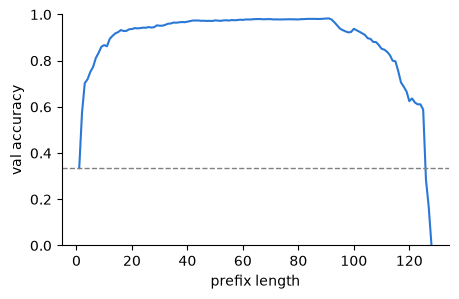

In [18]:
# accuracy vs. how much of the sequence the predictor has seen
ax = pd.Series(acc_by_len[1:].numpy(), index=range(1, data_train.max_length)).plot(
    figsize=(5, 3), color="#2a78d6", xlabel="prefix length", ylabel="val accuracy")
ax.axhline(1 / NUM_CLASSES, ls="--", c="grey", lw=1)   # chance
ax.set_ylim(0, 1)
ax.spines[["top", "right"]].set_visible(False)

In [19]:
# save both heads in results
torch.save({"head": head.state_dict(), "eval_head": eval_head.state_dict(),
            "hidden": X_train.shape[-1]}, "../results/classifier_head.pt")

In [20]:
head = ProteinFamilyClassifier(num_features=129, embedding_dim=32, num_hidden=128, num_output=NUM_CLASSES, vocab_size=VOCAB_SIZE).to(DEVICE)
eval_head = ProteinFamilyClassifier(num_features=129, embedding_dim=32, num_hidden=128, num_output=NUM_CLASSES, vocab_size=VOCAB_SIZE).to(DEVICE)

head.load_state_dict(torch.load("../results/classifier_head.pt", map_location=DEVICE)["head"])
eval_head.load_state_dict(torch.load("../results/classifier_head.pt", map_location=DEVICE)["eval_head"])

<All keys matched successfully>

## Guided generation

In [27]:
# for guided generation we reuse the sampler from phase 1 and only swap the logits it samples from
from protgen.models.rnn import sample

# guide generation towards HU family
TARGET = data_train.fam_to_idx["HU"]
SEED = 42
lambdas = [0.0, 1.0, 3.0, 10.0, 50.0, 100.0]

def guidance(lam):
    @torch.no_grad()
    def logit_fn(logits, state, i, hist):
        B, V = logits.shape
        cand = hist.repeat_interleave(V, dim=0)                       # (B*V, T): row b*V+v = sequence b
        cand[:, i + 1] = torch.arange(V, device=hist.device).repeat(B)  # put candidate v after the prefix
        logp_y = F.log_softmax(head(cand), dim=-1)[:, TARGET].view(B, V)
        out = logits + lam * logp_y
        out[:, [0, 1]] = float("-inf") # <PAD>, <BOS>
        return out
    return logit_fn

# run for different guidance strengths
for lam in lambdas:
    torch.manual_seed(SEED)
    seqs = sample(encoder, n=500, logit_fn=guidance(lam))   # lam=0 --> our unguided baseline
    pd.DataFrame({"sequence": seqs}).to_csv(
        f"../results/sequences/guided_lambda{lam:g}.csv", index=False)

In [28]:
# predicted family of finished sequences
# score with eval_head as stated above
@torch.no_grad()
def predict_family(seqs, model):
    model.eval()                                                      
    X = torch.stack([data_train.encode(s) for s in seqs]).to(DEVICE)  
    return model(X).argmax(-1).cpu() 

# sanity check on real proteins, should roughly recover the true families
real = data_val.df.sequence[:300]
print(pd.crosstab(data_val.df.family[:300], [FAMILIES[i] for i in predict_family(real, eval_head)]))

col_0   AcyP  HPr   HU
family                
AcyP      97    0    0
HPr        1   94    2
HU         0    2  104


In [29]:
# target-family membership vs guidance strength
# and length distribution per guidance strength (making sure that strong lambda doesn't distort how long sequences get)
# should we plot this? Table is probs better in report?
membership = {}
rows = {}
lambdas = [0.0, 1.0, 3.0, 10.0, 50.0, 100.0]
CAP = data_train.max_length - 2

for lam in lambdas:
    seqs = pd.read_csv(f"../results/sequences/guided_lambda{lam:g}.csv").sequence
    L = seqs.str.len()

    membership[lam] = (predict_family(seqs, eval_head) == TARGET).float().mean().item()
    rows[lam] = {"min": L.min(), "median": L.median(), "mean": L.mean(),
                 "max": L.max(), "frac_at_cap": (L >= CAP).mean()}

lengths_by_lam = pd.DataFrame(rows).T.round(1)
lengths_by_lam.index.name = "lambda"    

print(pd.Series(membership, name=f"fraction predicted {FAMILIES[TARGET]}"))

# real proteins of the target family, as a reference for what lengths should look like
ref = data_val.df.sequence[data_val.df.family == FAMILIES[TARGET]].str.len()
print(f"real {FAMILIES[TARGET]} (n={len(ref)}): "
      f"min {ref.min()}, median {ref.median():.0f}, mean {ref.mean():.1f}, max {ref.max()}\n")
print(lengths_by_lam)

0.0      0.322
1.0      0.824
3.0      0.988
10.0     1.000
50.0     0.998
100.0    0.998
Name: fraction predicted HU, dtype: float64
real HU (n=667): min 90, median 90, mean 92.8, max 125

         min  median  mean    max  frac_at_cap
lambda                                        
0.0     25.0    92.0  94.8  127.0          0.0
1.0     67.0    92.0  94.8  127.0          0.0
3.0     87.0    91.0  92.0  127.0          0.0
10.0    87.0    90.0  90.9  113.0          0.0
50.0    28.0    90.0  90.8  126.0          0.0
100.0   88.0    90.0  90.8  121.0          0.0
